In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("Sample - Superstore.csv", encoding="latin1")

# Rename required columns to match the lab manual
df = df.rename(columns={
    "Order Date": "order_date",
    "Region": "region",
    "Category": "category",
    "Sub-Category": "sub_category",
    "Discount": "discount",
    "Profit": "profit",
    "Sales": "sales",
    "Quantity": "quantity"
})

# Convert order_date to datetime
df["order_date"] = pd.to_datetime(df["order_date"], format="%m/%d/%Y")

# Display basic information
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.head()

Dataset shape: (9994, 21)

Columns:
['Row ID', 'Order ID', 'order_date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'region', 'Product ID', 'category', 'sub_category', 'Product Name', 'sales', 'quantity', 'discount', 'profit']


,Row ID,Order ID,order_date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,region,Product ID,category,sub_category,Product Name,sales,quantity,discount,profit
0,1,CA-2016-152156,2016-11-08,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


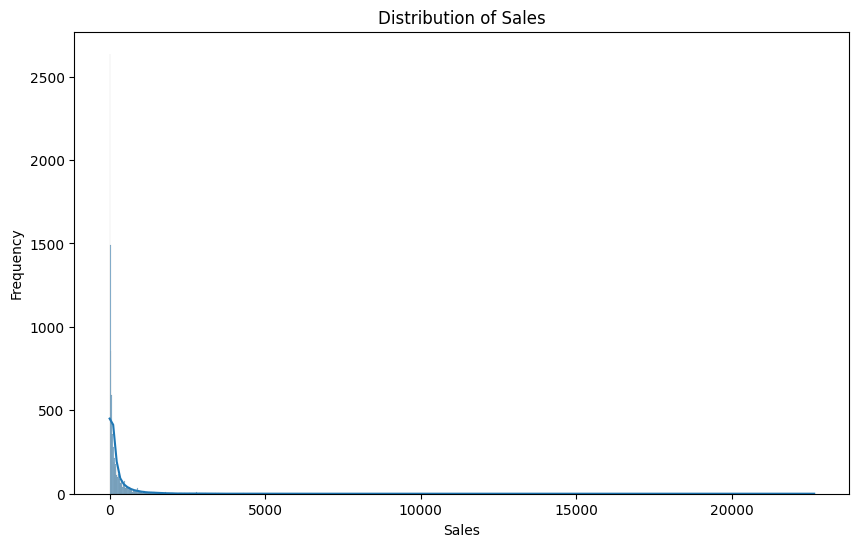

Sales skewness: 12.9728
Mean sales: 229.8580
Median sales: 54.4900


In [3]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="sales",
    kde=True
)

plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()

skewness = df["sales"].skew()
mean_sales = df["sales"].mean()
median_sales = df["sales"].median()

print(f"Sales skewness: {skewness:.4f}")
print(f"Mean sales: {mean_sales:.4f}")
print(f"Median sales: {median_sales:.4f}")

The sales distribution is highly right-skewed because the skewness is positive and large (approximately 12.97), with the mean (229.86) much greater than the median (54.49). Therefore, the mean is strongly influenced by a relatively small number of very large sales values, so the median is a more representative measure of a typical transaction.

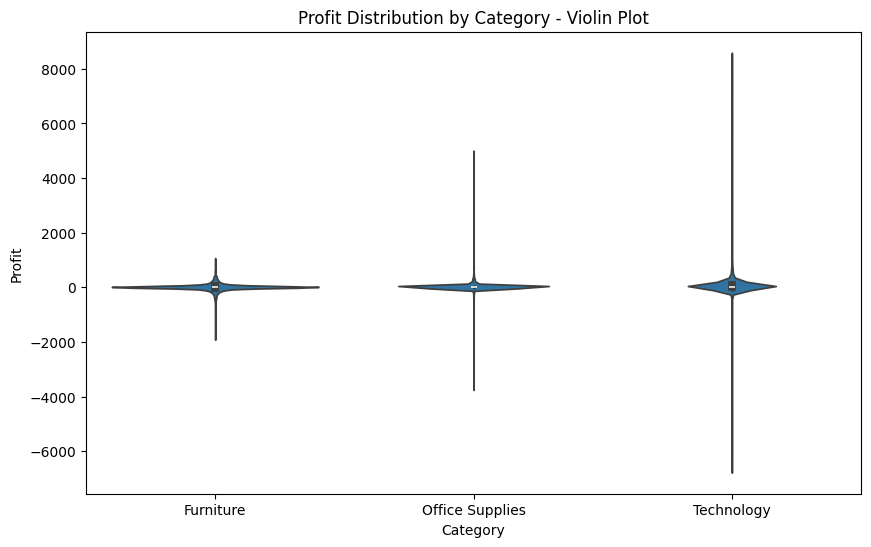

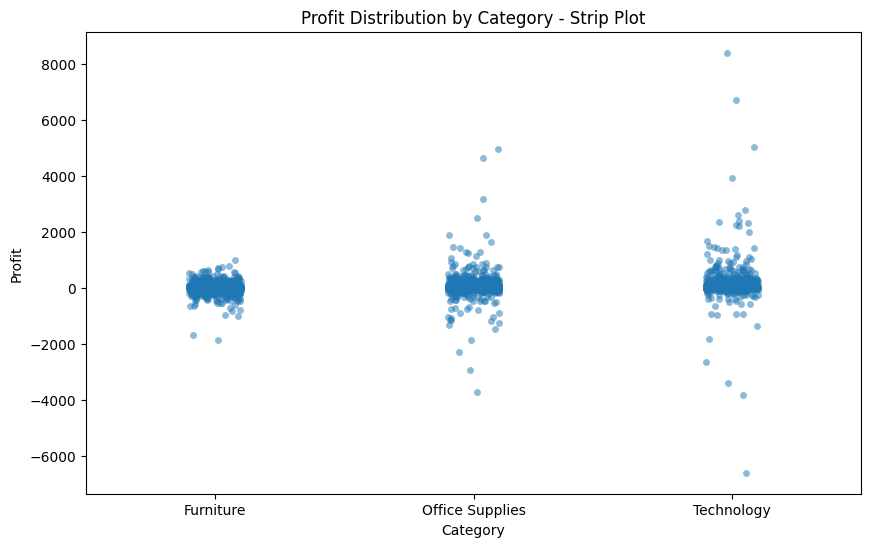

In [4]:
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df,
    x="category",
    y="profit"
)

plt.title("Profit Distribution by Category - Violin Plot")
plt.xlabel("Category")
plt.ylabel("Profit")
plt.show()


plt.figure(figsize=(10, 6))

sns.stripplot(
    data=df,
    x="category",
    y="profit",
    jitter=True,
    alpha=0.5
)

plt.title("Profit Distribution by Category - Strip Plot")
plt.xlabel("Category")
plt.ylabel("Profit")
plt.show()

The violin plot better reveals a bimodal or unusually spread-out profit distribution because it shows the overall density and shape of the distribution for each category. The strip plot shows individual observations clearly, but overlapping points make the overall distribution harder to judge for large groups.

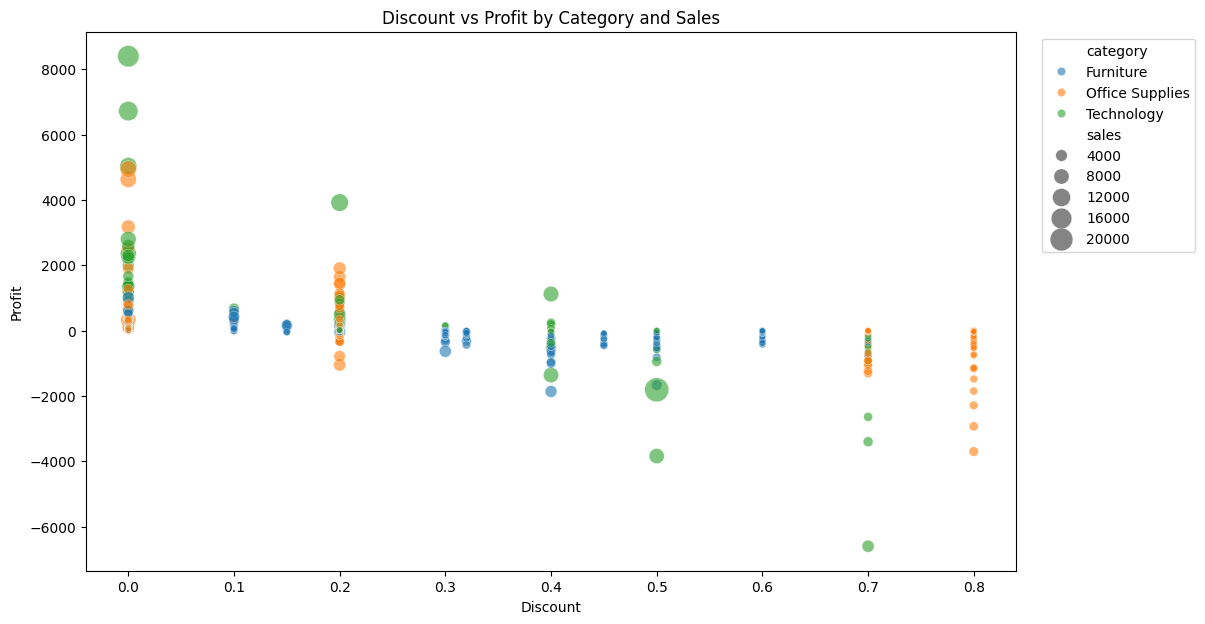

In [5]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df,
    x="discount",
    y="profit",
    hue="category",
    size="sales",
    sizes=(20, 300),
    alpha=0.6
)

plt.title("Discount vs Profit by Category and Sales")
plt.xlabel("Discount")
plt.ylabel("Profit")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

The four-variable encoding makes it possible to see that high-discount transactions tend to be associated with lower profits, while the size of the points shows that some high-sales transactions occur at both profitable and unprofitable discount levels. This pattern would be difficult to see from a simple discount-versus-profit scatter plot without category and sales information.

In [6]:
# Select the main analytical numeric columns
numeric_cols = ["sales", "quantity", "discount", "profit"]

pearson_corr = df[numeric_cols].corr(method="pearson")
spearman_corr = df[numeric_cols].corr(method="spearman")

print("Pearson Correlation Matrix:")
display(pearson_corr.round(4))

print("\nSpearman Correlation Matrix:")
display(spearman_corr.round(4))

# Show the pair with the largest Pearson/Spearman difference
difference = (pearson_corr - spearman_corr).abs()

# Remove diagonal
np.fill_diagonal(difference.values, 0)

pair = difference.stack().idxmax()
max_difference = difference.loc[pair[0], pair[1]]

print(f"\nLargest noticeable disagreement: {pair[0]} vs {pair[1]}")
print(f"Pearson correlation: {pearson_corr.loc[pair[0], pair[1]]:.4f}")
print(f"Spearman correlation: {spearman_corr.loc[pair[0], pair[1]]:.4f}")
print(f"Absolute difference: {max_difference:.4f}")

Pearson Correlation Matrix:


,sales,quantity,discount,profit
sales,1.0000,0.2008,-0.0282,0.4791
quantity,0.2008,1.0000,0.0086,0.0663
discount,-0.0282,0.0086,1.0000,-0.2195
profit,0.4791,0.0663,-0.2195,1.0000



Spearman Correlation Matrix:


,sales,quantity,discount,profit
sales,1.0000,0.3274,-0.0570,0.5184
quantity,0.3274,1.0000,-0.0009,0.2345
discount,-0.0570,-0.0009,1.0000,-0.5434
profit,0.5184,0.2345,-0.5434,1.0000



Largest noticeable disagreement: discount vs profit
Pearson correlation: -0.2195
Spearman correlation: -0.5434
Absolute difference: 0.3239


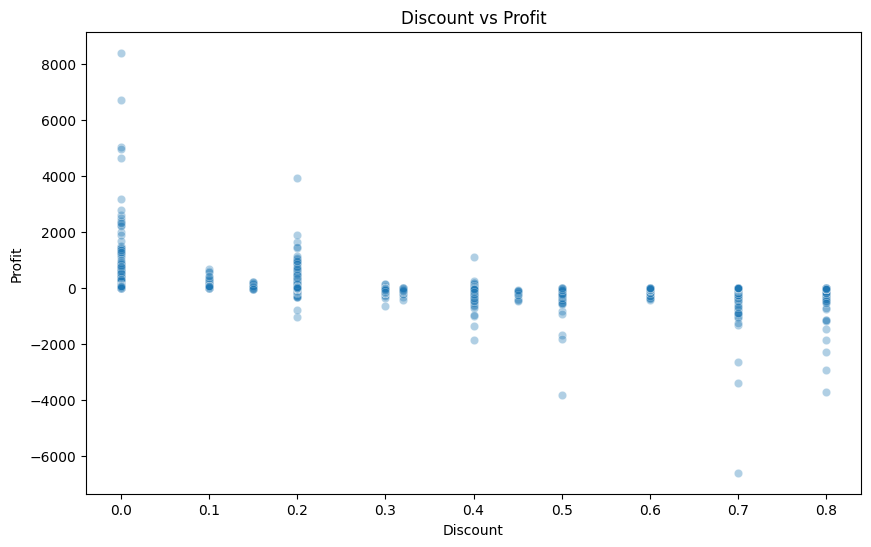

In [7]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="discount",
    y="profit",
    alpha=0.35
)

plt.title("Discount vs Profit")
plt.xlabel("Discount")
plt.ylabel("Profit")
plt.show()

The noticeable disagreement is between Discount and Profit: Pearson correlation is approximately -0.219, while Spearman correlation is approximately -0.543. The stronger negative Spearman value indicates that the relationship is more consistently monotonic in rank than linear, while the Pearson value is affected by the non-linear pattern and extreme profit/loss observations. Correlation does not imply causation; the two variables may be related because of other factors or by coincidence.

In [8]:
sales_pivot = pd.pivot_table(
    df,
    index="region",
    columns="category",
    values="sales",
    aggfunc="sum",
    margins=True
)

display(sales_pivot.round(2))

category,Furniture,Office Supplies,Technology,All
region,,,,
Central,163797.16,167026.42,170416.31,501239.89
East,208291.20,205516.06,264973.98,678781.24
South,117298.68,125651.31,148771.91,391721.90
West,252612.74,220853.25,251991.83,725457.82
All,741999.80,719047.03,836154.03,2297200.86


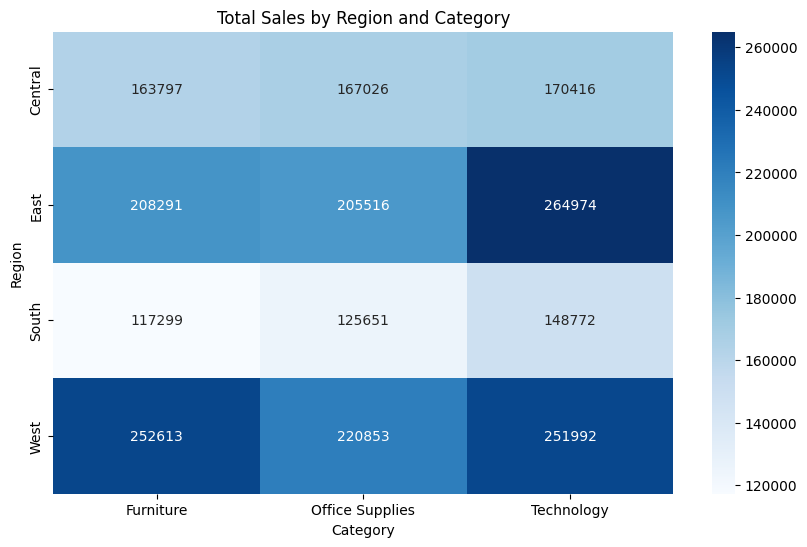

Highest region-category contribution: East - Technology = $264,973.98


In [9]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    sales_pivot.iloc[:-1, :-1],
    annot=True,
    fmt=".0f",
    cmap="Blues"
)

plt.title("Total Sales by Region and Category")
plt.xlabel("Category")
plt.ylabel("Region")
plt.show()

# Find the region-category combination with the highest sales
region_category_sales = sales_pivot.iloc[:-1, :-1]
max_region, max_category = region_category_sales.stack().idxmax()
max_value = region_category_sales.loc[max_region, max_category]

print(
    f"Highest region-category contribution: "
    f"{max_region} - {max_category} = ${max_value:,.2f}"
)

The West region–Furniture combination contributes the most revenue among the individual region–category combinations, with total sales of approximately $252,612.74.

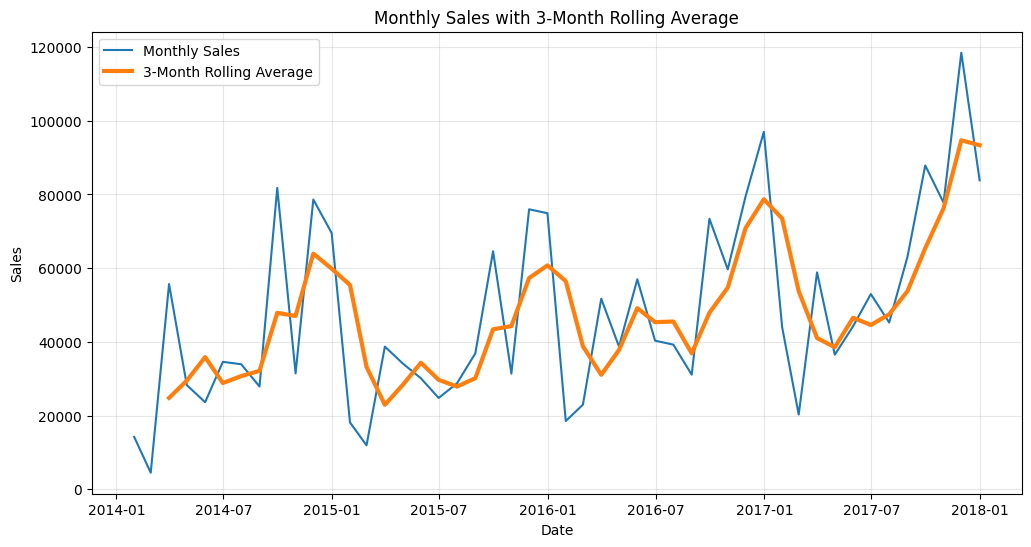

In [10]:
# Set order_date as the index
time_df = df.set_index("order_date").sort_index()

# Monthly total sales
monthly_sales = time_df["sales"].resample("ME").sum()

# 3-month rolling average
rolling_sales = monthly_sales.rolling(window=3).mean()

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    label="Monthly Sales"
)

plt.plot(
    rolling_sales.index,
    rolling_sales.values,
    label="3-Month Rolling Average",
    linewidth=3
)

plt.title("Monthly Sales with 3-Month Rolling Average")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

The raw monthly sales line shows short-term fluctuations and noise that make the underlying pattern harder to identify. The 3-month rolling average smooths these fluctuations and makes the overall sales trend easier to see, including sustained increases or decreases over time.

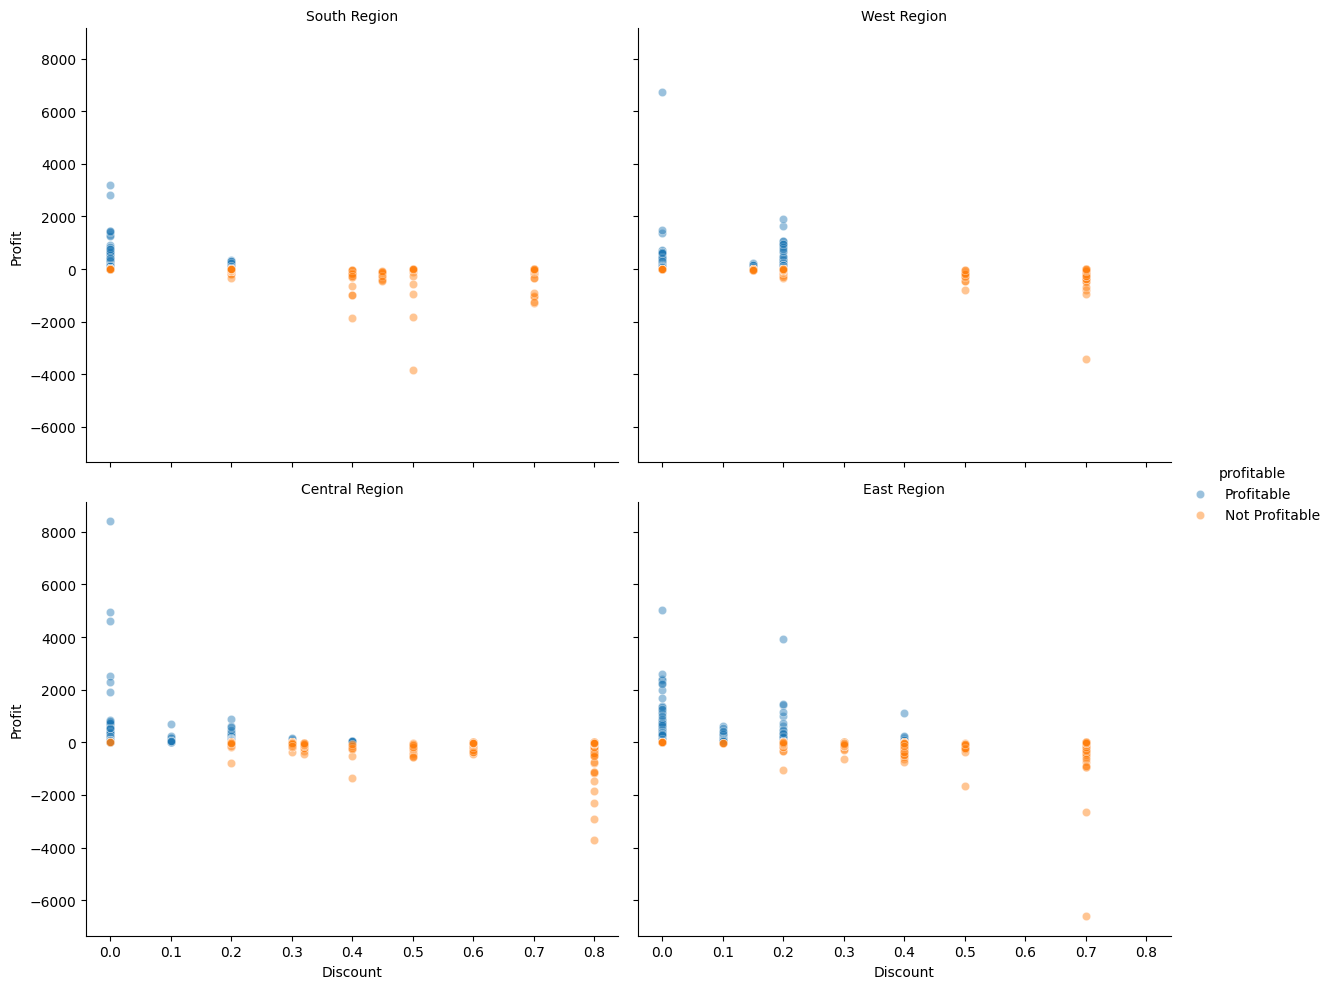

In [12]:
# Create profitable/non-profitable variable
df["profitable"] = np.where(df["profit"] > 0, "Profitable", "Not Profitable")

g = sns.FacetGrid(
    df,
    col="region",
    hue="profitable",
    col_wrap=2,
    height=5,
    aspect=1.2
)

g.map(
    sns.scatterplot,
    "discount",
    "profit",
    alpha=0.45
)

g.add_legend()

g.set_axis_labels("Discount", "Profit")
g.set_titles("{col_name} Region")

plt.show()

The West region visibly differs from the others because the discount–profit relationship appears somewhat less strongly negative there, with profitable observations remaining visible across a wider range of discount levels. The other regions show a more noticeable concentration of losses as discount increases.

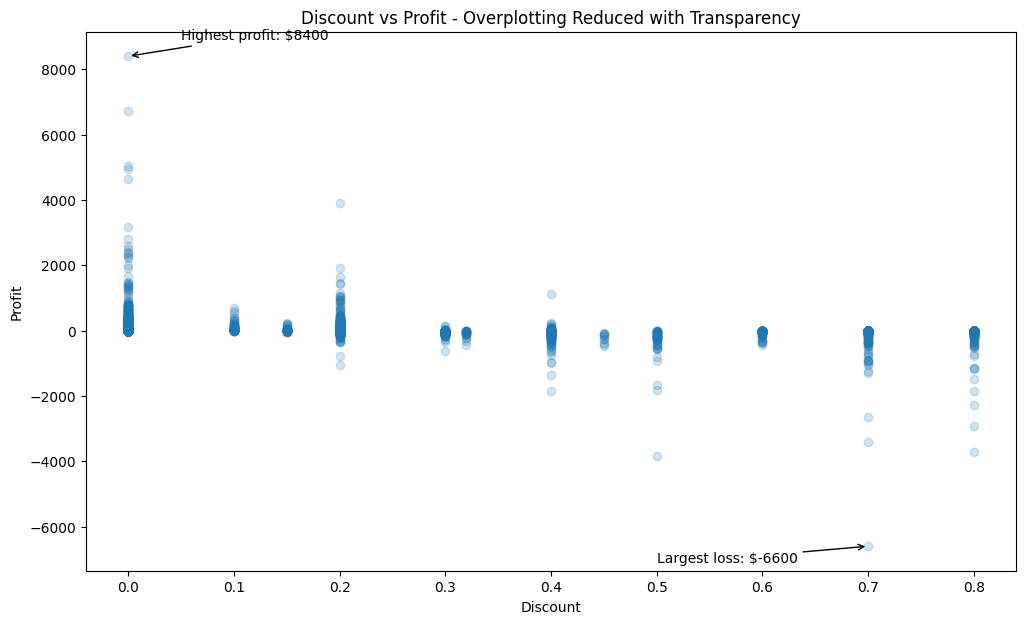

Most profitable order:
Order ID    CA-2016-118689
sales             17499.95
discount               0.0
profit            8399.976
Name: 6826, dtype: object

Largest loss order:
Order ID    CA-2016-108196
sales             4499.985
discount               0.7
profit           -6599.978
Name: 7772, dtype: object


In [13]:
# Raw order-level scatter with transparency to reduce overplotting
plt.figure(figsize=(12, 7))

plt.scatter(
    df["discount"],
    df["profit"],
    alpha=0.2
)

# Find most profitable order and largest loss
best = df.loc[df["profit"].idxmax()]
worst = df.loc[df["profit"].idxmin()]

# Annotate highest profit
plt.annotate(
    f"Highest profit: ${best['profit']:.0f}",
    xy=(best["discount"], best["profit"]),
    xytext=(best["discount"] + 0.05, best["profit"] + 500),
    arrowprops=dict(arrowstyle="->")
)

# Annotate largest loss
plt.annotate(
    f"Largest loss: ${worst['profit']:.0f}",
    xy=(worst["discount"], worst["profit"]),
    xytext=(worst["discount"] - 0.2, worst["profit"] - 500),
    arrowprops=dict(arrowstyle="->")
)

plt.title("Discount vs Profit - Overplotting Reduced with Transparency")
plt.xlabel("Discount")
plt.ylabel("Profit")
plt.show()

print("Most profitable order:")
print(best[["Order ID", "sales", "discount", "profit"]])

print("\nLargest loss order:")
print(worst[["Order ID", "sales", "discount", "profit"]])

Transparency (alpha) is suitable here because the dataset contains about 10,000 orders, which creates noticeable overlap but is still manageable with a transparent scatter plot rather than requiring hexbinning. The plot highlights the single most profitable order and the single largest loss using annotations.